# Music & Mental Health — Notebook 01: Cleaning, EDA and first genre effects

**Aim.** Quantify how each music genre and listening behaviour is associated with self-reported anxiety, depression, insomnia and OCD, then build validated models whose findings can support follow-up medical research.

**This notebook:** (1) load and audit the data, (2) documented cleaning, (3) EDA, (4) first genre-by-condition effect estimates with bootstrap CIs and multiple-testing correction, (5) a covariate-adjusted check.

**Read this first.** Scores are self-reported 0–10 ratings from a self-selected, cross-sectional survey. Everything here is an *association*, not a causal effect, and reverse causation (mood shaping music choice) is just as plausible as the reverse.

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'src').exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from mxmh.config import SEED, TARGETS, FREQ_MAP, GENRES, FREQ_COLS
from mxmh.data import load_raw, clean_data

rng = np.random.default_rng(SEED)
DATA_PATH = ROOT / 'data' / 'raw' / 'mxmh_survey_results.csv'
PROC, TAB, FIG = ROOT / 'data' / 'processed', ROOT / 'reports' / 'tables', ROOT / 'reports' / 'figures'
for p in (PROC, TAB, FIG): p.mkdir(parents=True, exist_ok=True)
raw = load_raw(DATA_PATH)
print(raw.shape, '|', len(GENRES), 'genres')

(736, 33) | 16 genres


## 1. Data audit

In [2]:
audit = pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum(),
                      'unique': raw.nunique()})
display(audit)
print('Duplicate rows (ignoring timestamp):', raw.drop(columns='Timestamp').duplicated().sum())
display(raw[['Age', 'Hours per day', 'BPM'] + TARGETS].describe().T.round(2))

,dtype,missing,unique
Timestamp,str,0,735
Age,float64,1,61
Primary streaming service,str,1,6
Hours per day,float64,0,27
While working,str,3,2
Instrumentalist,str,4,2
Composer,str,1,2
Fav genre,str,0,16
Exploratory,str,0,2
Foreign languages,str,4,2


Duplicate rows (ignoring timestamp): 0


,count,mean,std,min,25%,50%,75%,max
Age,735.0,25.21,12.05,10.0,18.0,21.0,28.0,89.0
Hours per day,736.0,3.57,3.03,0.0,2.0,3.0,5.0,24.0
BPM,629.0,1589948.34,39872606.18,0.0,100.0,120.0,144.0,999999999.0
Anxiety,736.0,5.84,2.79,0.0,4.0,6.0,8.0,10.0
Depression,736.0,4.80,3.03,0.0,2.0,5.0,7.0,10.0
Insomnia,736.0,3.74,3.09,0.0,1.0,3.0,6.0,10.0
OCD,736.0,2.64,2.84,0.0,0.0,2.0,5.0,10.0


## 2. Cleaning (every rule is logged)

| Rule | Reason |
|---|---|
| Drop `Timestamp`, `Permissions` | No analytical value (Permissions is constant) |
| `BPM` outside 40–250 → NaN | Values such as 999,999,999, 624, 0, 4 and 8 are impossible; 208–220 are plausible and kept |
| `Hours per day` > 16 → NaN | 18, 20 and 24 hours of daily listening are implausible |
| Keep all ages, add `age_group` | Ages 10–17 are real respondents; flagged so they can be analysed separately |
| Keep missing values as NaN | Imputation happens later inside cross-validation pipelines to avoid leakage |
| Encode frequency columns 0–3 | Ordinal: Never < Rarely < Sometimes < Very frequently |

In [3]:
df, log = clean_data(raw)   # rules live in src/mxmh/data.py
display(pd.DataFrame(log, columns=['cleaning step', 'rows affected']))
df.to_csv(PROC / 'mxmh_clean.csv', index=False)
print('Saved cleaned data:', df.shape)

,cleaning step,rows affected
0,BPM outside 40-250 set to NaN,8
1,BPM missing after cleaning,115
2,Hours per day > 16 set to NaN,5
3,"Respondents under 18 (kept, flagged via age_gr...",153
4,Missing Age,1


Saved cleaned data: (736, 38)


## 3. EDA

### 3.1 The four outcomes

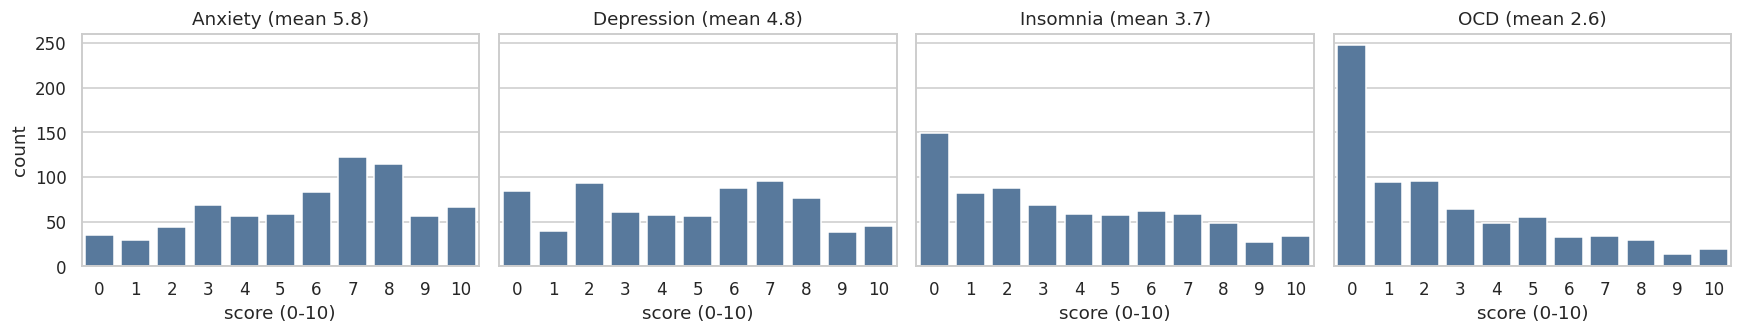

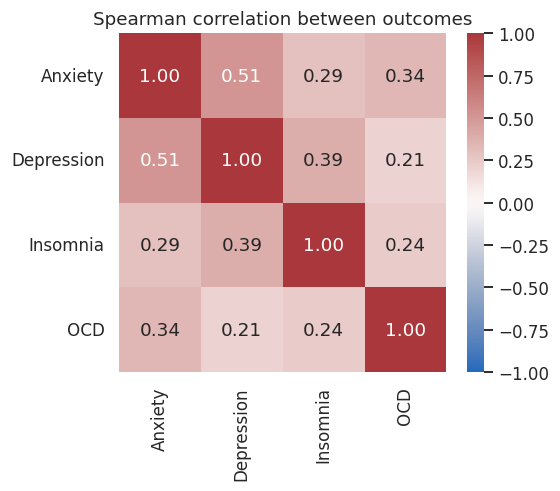

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2), sharey=True)
for ax, t in zip(axes, TARGETS):
    sns.countplot(x=df[t].astype(int), ax=ax, color='#4C78A8')
    ax.set_title(f'{t} (mean {df[t].mean():.1f})'); ax.set_xlabel('score (0-10)')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(4.8, 4))
sns.heatmap(df[TARGETS].corr(method='spearman'), annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('Spearman correlation between outcomes'); plt.show()

### 3.2 Listeners and habits

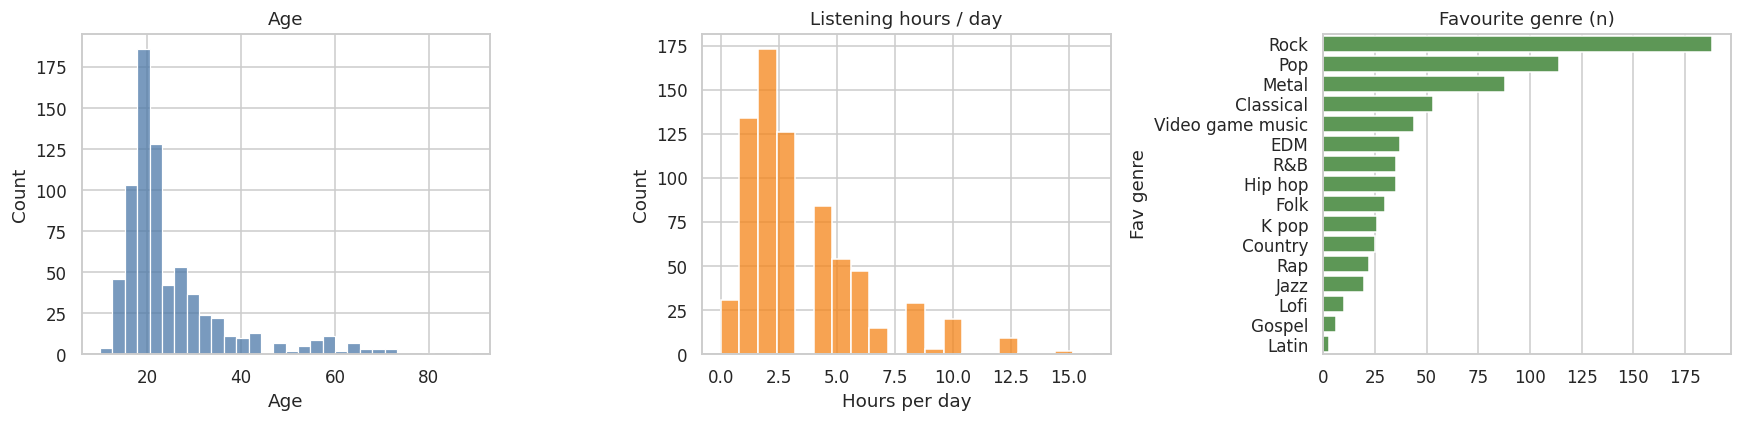

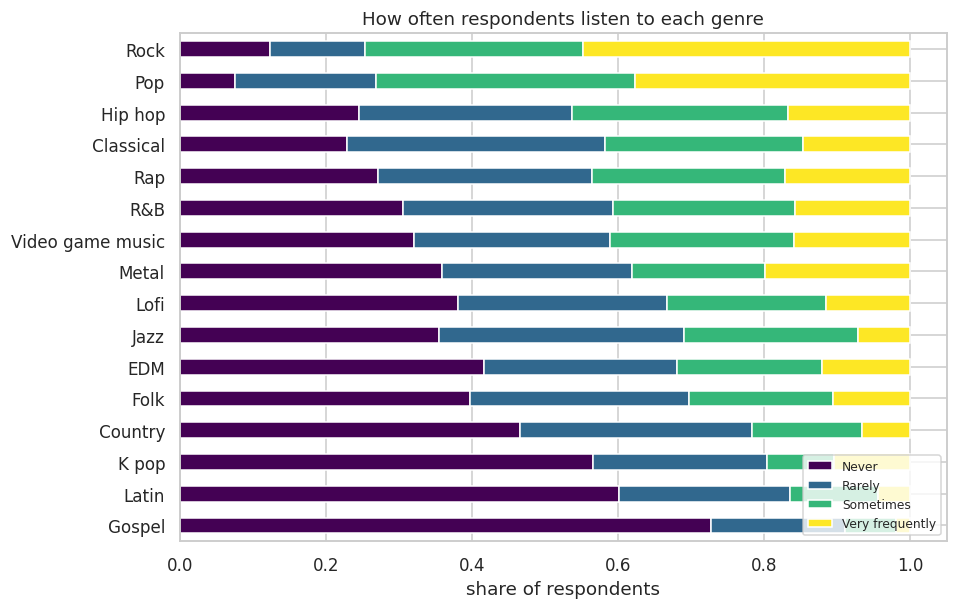

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df['Age'].dropna(), bins=30, ax=axes[0], color='#4C78A8'); axes[0].set_title('Age')
sns.histplot(df['Hours per day'].dropna(), bins=20, ax=axes[1], color='#F58518'); axes[1].set_title('Listening hours / day')
fav = df['Fav genre'].value_counts()
sns.barplot(x=fav.values, y=fav.index, ax=axes[2], color='#54A24B'); axes[2].set_title('Favourite genre (n)')
plt.tight_layout(); plt.show()

order = df[FREQ_COLS].mean().sort_values(ascending=False).index
lvl = pd.DataFrame({c.replace('freq_', ''): df[c].value_counts(normalize=True).reindex([0, 1, 2, 3]).fillna(0)
                    for c in order}).T
lvl.columns = list(FREQ_MAP)
lvl.plot(kind='barh', stacked=True, figsize=(9, 6), colormap='viridis')
plt.title('How often respondents listen to each genre'); plt.xlabel('share of respondents')
plt.gca().invert_yaxis(); plt.legend(loc='lower right', fontsize=8); plt.show()

In [6]:
print('Mean score by age group:')
display(df.groupby('age_group')[TARGETS].agg('mean').round(2).assign(n=df['age_group'].value_counts()))
df['hours_bin'] = pd.cut(df['Hours per day'], [-0.1, 1, 3, 5, 8, 16], labels=['<=1', '1-3', '3-5', '5-8', '8+'])
print('Mean score by listening hours:')
display(df.groupby('hours_bin')[TARGETS].mean().round(2).assign(n=df['hours_bin'].value_counts()))

Mean score by age group:


,Anxiety,Depression,Insomnia,OCD,n
age_group,,,,,
<18,6.05,4.56,3.87,3.03,153
18-24,5.97,5.01,3.54,2.71,334
25-34,6.17,5.44,3.96,2.67,144
35+,4.62,3.59,3.89,1.76,104


Mean score by listening hours:


,Anxiety,Depression,Insomnia,OCD,n
hours_bin,,,,,
<=1,5.41,4.21,3.21,1.99,148
1-3,5.81,4.69,3.58,2.55,316
3-5,6.27,5.33,4.08,2.95,138
5-8,5.73,4.71,4.07,3.12,91
8+,6.45,6.21,4.97,3.34,38


## 4. Part A, first results: genre × condition associations

Method: Spearman correlation (the frequency scale is ordinal), a 2,000-sample bootstrap 95% CI (computed on pre-ranked data, a standard fast approximation), and Benjamini–Hochberg FDR correction across all 64 genre-condition pairs. The CI matters more than the p-value: it shows how large and how uncertain each effect is.

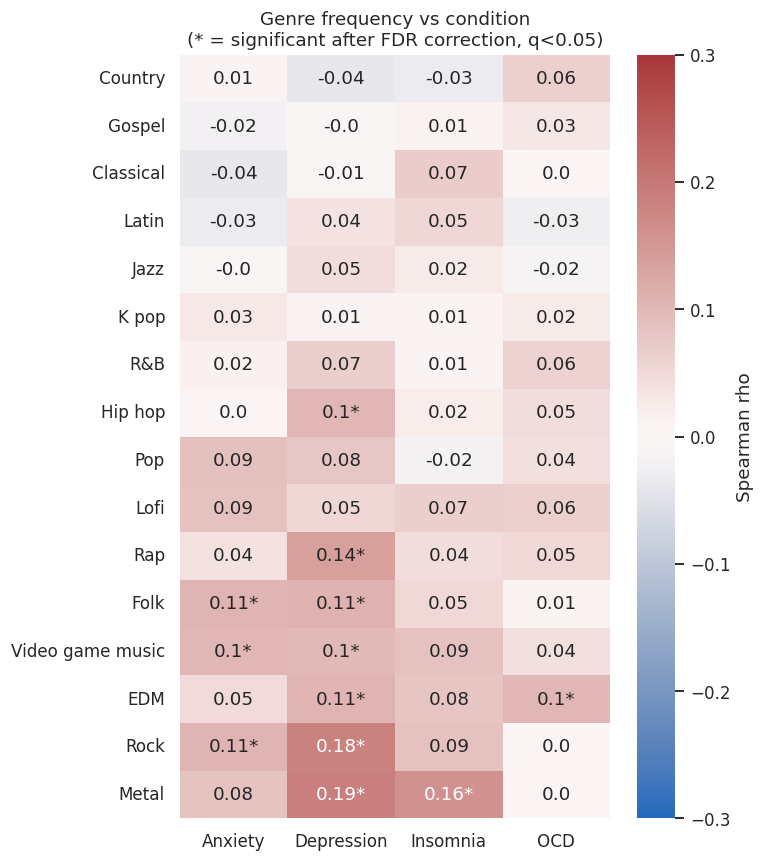

Significant after FDR: 12 of 64


,genre,condition,rho,p,n,q_fdr,ci_lo,ci_hi,significant_fdr05
0,Metal,Depression,0.189,0.000,736,0.000,0.121,0.260,True
1,Rock,Depression,0.184,0.000,736,0.000,0.108,0.257,True
2,Metal,Insomnia,0.160,0.000,736,0.000,0.087,0.233,True
3,Rap,Depression,0.138,0.000,736,0.003,0.064,0.213,True
4,Folk,Depression,0.110,0.003,736,0.031,0.040,0.180,True
5,Rock,Anxiety,0.107,0.004,736,0.031,0.033,0.180,True
6,EDM,Depression,0.107,0.004,736,0.031,0.036,0.181,True
7,Folk,Anxiety,0.106,0.004,736,0.031,0.038,0.175,True
8,Hip hop,Depression,0.101,0.006,736,0.034,0.030,0.175,True
9,EDM,OCD,0.101,0.006,736,0.034,0.027,0.172,True


In [7]:
rows = []
for g in GENRES:
    for t in TARGETS:
        sub = df[[f'freq_{g}', t]].dropna()
        rho, p = stats.spearmanr(sub[f'freq_{g}'], sub[t])
        rows.append({'genre': g, 'condition': t, 'rho': rho, 'p': p, 'n': len(sub)})
eff = pd.DataFrame(rows)
eff['q_fdr'] = multipletests(eff['p'], method='fdr_bh')[1]

# bootstrap CIs on average ranks
R = df[FREQ_COLS + TARGETS].dropna().rank().to_numpy()
n, B = len(R), 2000
boot = np.empty((B, len(FREQ_COLS), len(TARGETS)))
for b in range(B):
    s = R[rng.integers(0, n, n)]
    cm = np.corrcoef(s, rowvar=False)
    boot[b] = cm[:len(FREQ_COLS), len(FREQ_COLS):]
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
eff['ci_lo'] = [lo[GENRES.index(g), TARGETS.index(t)] for g, t in zip(eff.genre, eff.condition)]
eff['ci_hi'] = [hi[GENRES.index(g), TARGETS.index(t)] for g, t in zip(eff.genre, eff.condition)]
eff['significant_fdr05'] = eff['q_fdr'] < 0.05
eff.round(4).to_csv(TAB / 'genre_condition_effects.csv', index=False)

piv = eff.pivot(index='genre', columns='condition', values='rho')[TARGETS]
sig = eff.pivot(index='genre', columns='condition', values='q_fdr')[TARGETS]
annot = piv.round(2).astype(str) + sig.map(lambda q: '*' if q < 0.05 else '')
piv = piv.loc[piv.mean(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(7, 8))
sns.heatmap(piv, annot=annot.loc[piv.index], fmt='', cmap='vlag', center=0, vmin=-0.3, vmax=0.3, ax=ax, cbar_kws={'label': 'Spearman rho'})
ax.set_title('Genre frequency vs condition\n(* = significant after FDR correction, q<0.05)'); ax.set_ylabel(''); ax.set_xlabel('')
plt.tight_layout(); fig.savefig(FIG / 'genre_condition_heatmap.png', dpi=150); plt.show()

print('Significant after FDR:', int(eff.significant_fdr05.sum()), 'of', len(eff))
display(eff.sort_values('rho', key=abs, ascending=False).head(12).round(3).reset_index(drop=True))

### Forest plot: effect sizes with uncertainty

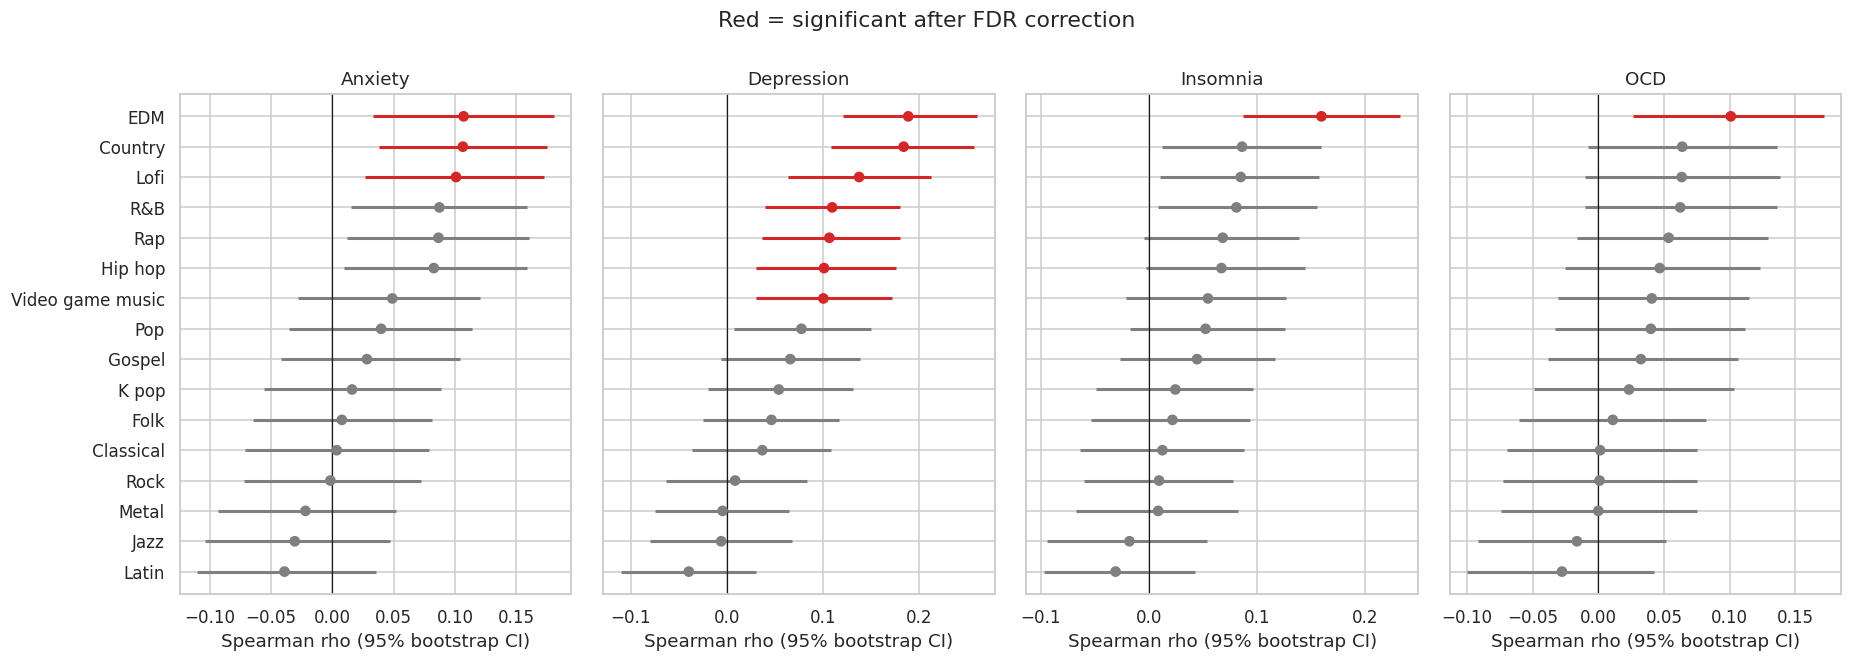

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(17, 6), sharey=True)
for ax, t in zip(axes, TARGETS):
    d = eff[eff.condition == t].sort_values('rho').reset_index(drop=True)
    colors = np.where(d.significant_fdr05, '#D62728', '#7F7F7F')
    ax.hlines(d.index, d.ci_lo, d.ci_hi, color=colors, lw=2)
    ax.scatter(d.rho, d.index, color=colors, zorder=3)
    ax.axvline(0, color='k', lw=0.8); ax.set_yticks(d.index); ax.set_yticklabels(d.genre)
    ax.set_title(t); ax.set_xlabel('Spearman rho (95% bootstrap CI)')
plt.suptitle('Red = significant after FDR correction', y=1.0); plt.tight_layout(); plt.show()

### Dose-response: does the score rise steadily with listening frequency?

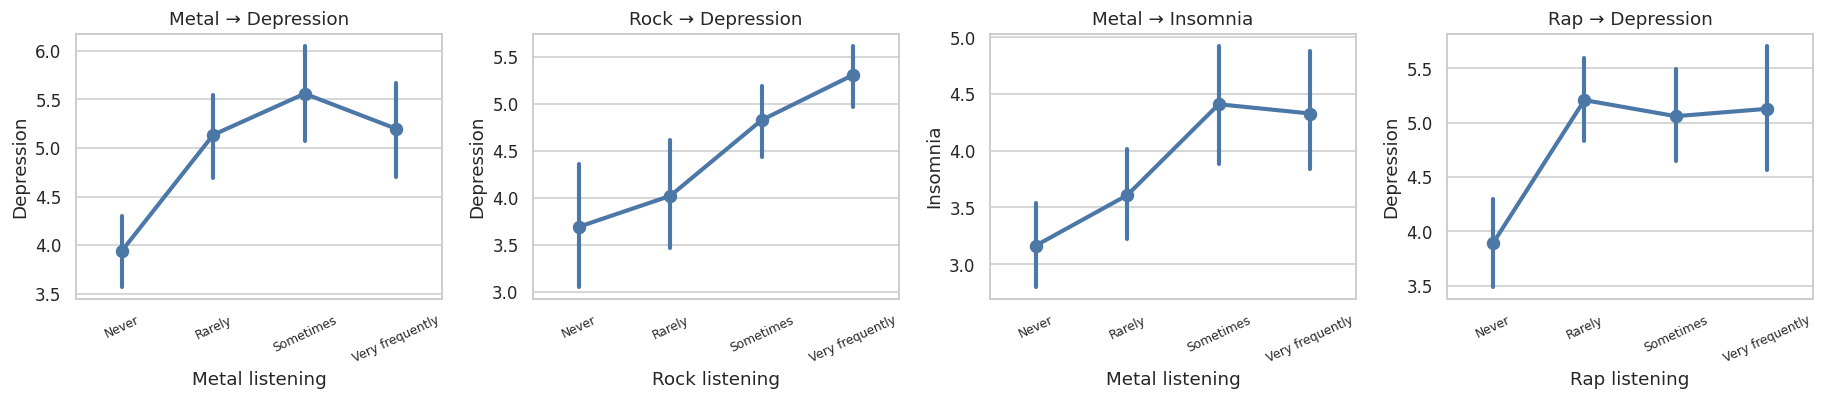

In [9]:
top = eff[eff.significant_fdr05].sort_values('rho', key=abs, ascending=False)
pairs = list(zip(top.genre, top.condition))[:4] or list(zip(eff.sort_values('p').genre, eff.sort_values('p').condition))[:4]
fig, axes = plt.subplots(1, len(pairs), figsize=(4.2 * len(pairs), 3.8), sharey=False)
axes = np.atleast_1d(axes)
for ax, (g, t) in zip(axes, pairs):
    sub = df[[f'freq_{g}', t]].dropna()
    sns.pointplot(data=sub, x=f'freq_{g}', y=t, errorbar=('ci', 95), color='#4C78A8', ax=ax)
    ax.set_xticks(range(4)); ax.set_xticklabels(list(FREQ_MAP), rotation=25, fontsize=8)
    ax.set_xlabel(f'{g} listening'); ax.set_title(f'{g} → {t}')
plt.tight_layout(); plt.show()

### Favourite genre (groups with at least 20 respondents only)

In [10]:
g = df.groupby('Fav genre')[TARGETS].agg(['mean']).droplevel(1, axis=1).round(2)
g['n'] = df['Fav genre'].value_counts()
g = g[g.n >= 20].sort_values('Depression')
display(g)
print('Excluded as too small:', sorted(set(df['Fav genre']) - set(g.index)))

,Anxiety,Depression,Insomnia,OCD,n
Fav genre,,,,,
R&B,5.17,3.83,2.89,2.74,35
Rap,5.09,4.00,2.27,3.18,22
Classical,4.89,4.08,3.79,2.38,53
Country,5.40,4.32,2.72,2.76,25
K pop,6.23,4.42,3.46,2.54,26
Video game music,5.89,4.48,4.00,2.39,44
Pop,6.07,4.49,3.37,2.86,114
Jazz,5.90,4.50,3.85,2.80,20
Folk,6.57,5.07,3.63,2.20,30


Excluded as too small: ['Gospel', 'Latin', 'Lofi']


## 5. Covariate-adjusted check

Raw correlations can be confounded. Here each condition is regressed on all 16 genre frequencies *together* with age, listening hours and instrument playing, using heteroskedasticity-robust (HC3) standard errors. A coefficient is the change in score per one-level increase in listening frequency, holding the other terms fixed. Effects that shrink or vanish here were probably explained by age or by overlap between genres.

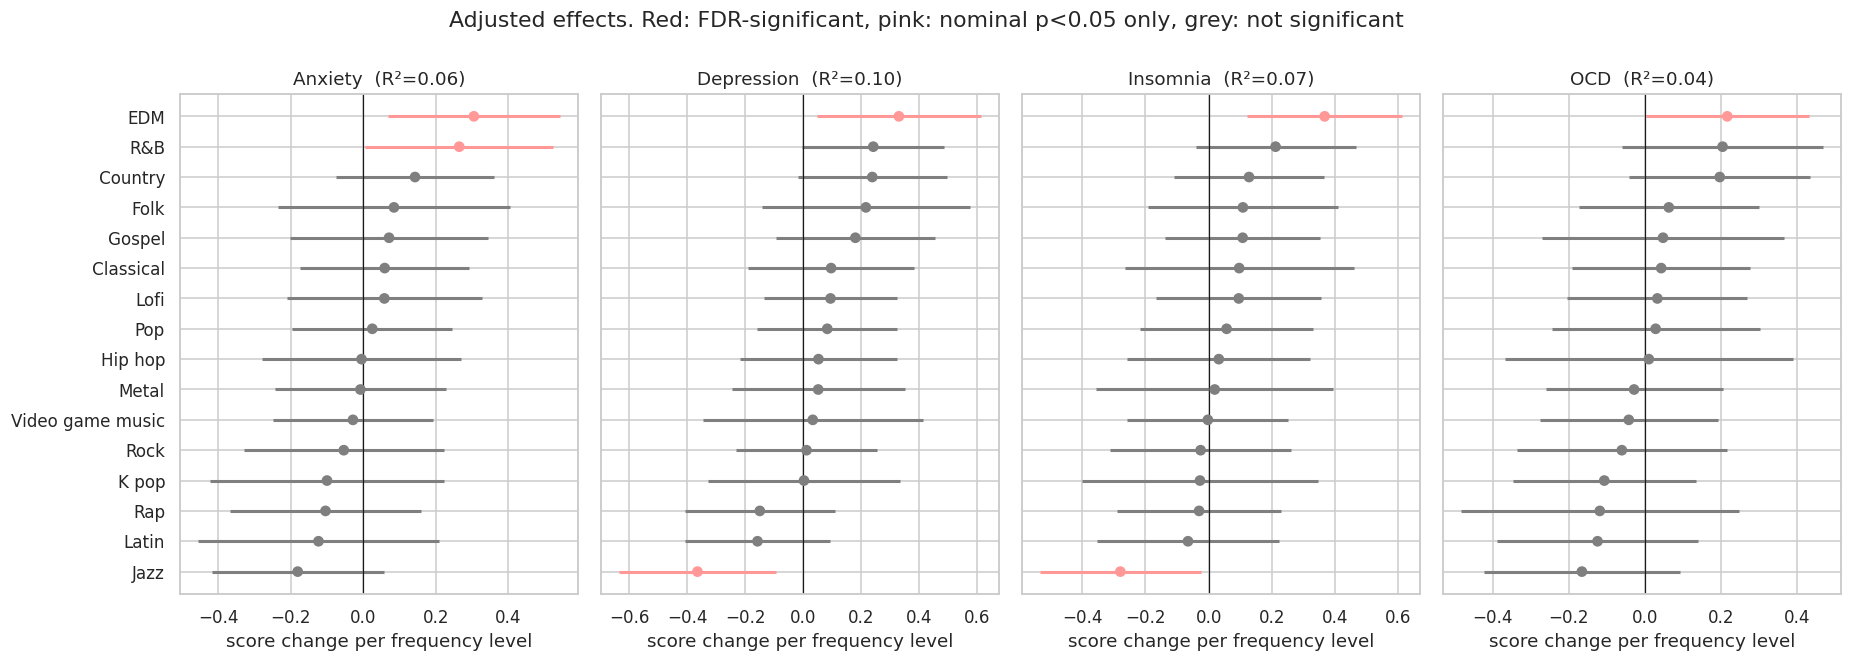

,genre,condition,rho,p_raw,coef,p_adj,q_fdr_adj
0,Metal,Insomnia,0.160,0.000,0.367,0.003,0.217
1,Country,Depression,-0.039,0.286,-0.364,0.008,0.250
2,Folk,Anxiety,0.106,0.004,0.305,0.012,0.250
3,Rock,Depression,0.184,0.000,0.330,0.022,0.359
4,Country,Insomnia,-0.031,0.404,-0.279,0.031,0.402
5,Pop,Anxiety,0.087,0.018,0.265,0.045,0.426
6,EDM,OCD,0.101,0.006,0.216,0.048,0.426
7,Metal,Depression,0.189,0.000,0.242,0.053,0.426
8,Folk,Depression,0.110,0.003,0.238,0.069,0.490
9,Video game music,Anxiety,0.101,0.006,0.143,0.196,0.817


In [11]:
safe = {g: 'g_' + g.replace(' ', '_').replace('&', 'and') for g in GENRES}
adj = df.rename(columns={f'freq_{g}': safe[g] for g in GENRES}).rename(
    columns={'Hours per day': 'hours', 'Instrumentalist': 'instrumentalist'})
formula_rhs = ' + '.join(safe.values()) + ' + Age + hours + instrumentalist'
adj_rows = []
for t in TARGETS:
    m = smf.ols(f'{t} ~ {formula_rhs}', data=adj).fit(cov_type='HC3')
    ci = m.conf_int()
    for g in GENRES:
        k = safe[g]
        adj_rows.append({'genre': g, 'condition': t, 'coef': m.params[k], 'ci_lo': ci.loc[k, 0],
                         'ci_hi': ci.loc[k, 1], 'p': m.pvalues[k], 'n': int(m.nobs), 'r2_model': m.rsquared})
adj_df = pd.DataFrame(adj_rows)
adj_df['q_fdr'] = multipletests(adj_df['p'], method='fdr_bh')[1]
adj_df.round(4).to_csv(TAB / 'genre_condition_adjusted.csv', index=False)

fig, axes = plt.subplots(1, 4, figsize=(17, 6), sharey=True)
for ax, t in zip(axes, TARGETS):
    d = adj_df[adj_df.condition == t].sort_values('coef').reset_index(drop=True)
    colors = np.where(d.q_fdr < 0.05, '#D62728', np.where(d.p < 0.05, '#FF9896', '#7F7F7F'))
    ax.hlines(d.index, d.ci_lo, d.ci_hi, color=colors, lw=2); ax.scatter(d.coef, d.index, color=colors, zorder=3)
    ax.axvline(0, color='k', lw=0.8); ax.set_yticks(d.index); ax.set_yticklabels(d.genre)
    ax.set_title(f'{t}  (R²={d.r2_model.iloc[0]:.2f})'); ax.set_xlabel('score change per frequency level')
plt.suptitle('Adjusted effects. Red: FDR-significant, pink: nominal p<0.05 only, grey: not significant', y=1.0)
plt.tight_layout(); plt.show()

cmp = eff.merge(adj_df[['genre', 'condition', 'coef', 'p', 'q_fdr']], on=['genre', 'condition'], suffixes=('_raw', '_adj'))
display(cmp[(cmp.p_raw < 0.05) | (cmp.p_adj < 0.05)].sort_values('p_adj')[
    ['genre', 'condition', 'rho', 'p_raw', 'coef', 'p_adj', 'q_fdr_adj']].round(3).reset_index(drop=True))

## 6. Summary of what this notebook establishes

In [12]:
print('Cleaned respondents:', len(df))
print('Raw pairs significant after FDR:', int(eff.significant_fdr05.sum()), '/ 64')
print('Adjusted pairs significant after FDR:', int((adj_df.q_fdr < 0.05).sum()), '/ 64;',
      'nominal p<0.05:', int((adj_df.p < 0.05).sum()))
print('Adjusted model R² by condition:', adj_df.groupby('condition').r2_model.first().round(3).to_dict())
print('Saved to', ROOT)

Cleaned respondents: 736
Raw pairs significant after FDR: 12 / 64
Adjusted pairs significant after FDR: 0 / 64; nominal p<0.05: 7
Adjusted model R² by condition: {'Anxiety': 0.061, 'Depression': 0.097, 'Insomnia': 0.065, 'OCD': 0.045}
Saved to /home/claude/music-mental-health-ml


### Next: notebook 02
Feature engineering (genre diversity, taste-profile clusters via NMF/PCA), repeated-CV predictive models against an age-and-hours baseline, calibration, SHAP, and the ranked hypothesis list for researchers.